# Human Preference Prediction for AI Responses
## Exploratory Data Analysis

### Project Objective

This project investigates whether classical Natural Language Processing (NLP) techniques can be used to predict human preferences between two candidate AI responses.

The dataset contains pairs of responses to the same user prompt:

- **Chosen response:** The response preferred by human annotators.
- **Rejected response:** The response that was not preferred.

The purpose of this exploratory analysis is to understand the linguistic characteristics of the dataset and determine whether there are observable differences between chosen and rejected responses.

### EDA Objectives

1. Understand the structure of the dataset.
2. Verify data quality and identify invalid or duplicate records.
3. Compare response lengths.
4. Analyze frequent words and n-grams.
5. Compare word distributions using word clouds.
6. Compare sentence counts between chosen and rejected responses.
7. Identify patterns that can guide subsequent machine-learning modeling.
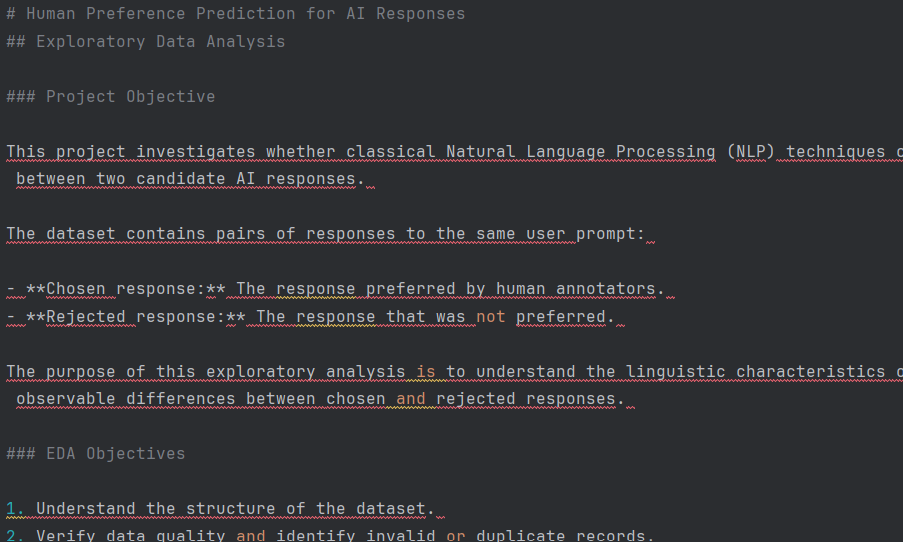

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter
from wordcloud import WordCloud

## 1. Dataset Overview

The cleaned dataset contains human preference pairs extracted from the Anthropic HH-RLHF dataset.

Each record contains:

- `prompt` — the final user prompt.
- `chosen_response` — the human-preferred response.
- `rejected_response` — the less-preferred response.

The analysis uses the cleaned dataset generated during the preprocessing stage.

In [32]:
df = pd.read_csv("../data/hh_rlhf_cleaned.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (9972, 3)


,prompt,chosen_response,rejected_response
0,"Okay. What else is needed to play, and what ar...",A horseshoe is usually made out of metal and i...,Horseshoes are either metal or plastic discs. ...
1,any other ideas? they are fidgeting,"Kids are great at fidgeting, so let’s make sur...","Yeah, definitely. What works for you personall..."
2,Thanks. And what are some typical forms required?,"At the marina level, there’s usually the renta...","Oh, I’m afraid I’m not very familiar with thes..."
3,How can I store food if I don't have a pantry?,"You could store the food in a refrigerator, th...",By storing food in your refrigerator or freeze...
4,That sounds cool,"I’m a programmer, so I’m really into good prog...",Do you want some quotes?


## 2. Data Quality Check

Before performing linguistic analysis, the dataset is checked for:

- Missing values
- Duplicate records
- Identical chosen and rejected responses
- Overall dataset size

Invalid preference pairs were removed during preprocessing.

In [33]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Number of rows: 9972
Number of columns: 3

Columns:
['prompt', 'chosen_response', 'rejected_response']

Missing values:
prompt               0
chosen_response      0
rejected_response    0
dtype: int64

Duplicate rows:
0


In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9972 entries, 0 to 9971
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   prompt             9972 non-null   str  
 1   chosen_response    9972 non-null   str  
 2   rejected_response  9972 non-null   str  
dtypes: str(3)
memory usage: 4.9 MB


## 3. Response Length Analysis

Response length is analyzed using:

- Word count
- Character count

The purpose is to investigate whether human-preferred responses tend to be longer or shorter than rejected responses.

However, response length alone should not be assumed to determine human preference.

In [35]:
df["chosen_words"] = df["chosen_response"].str.split().str.len()
df["rejected_words"] = df["rejected_response"].str.split().str.len()

df["chosen_chars"] = df["chosen_response"].str.len()
df["rejected_chars"] = df["rejected_response"].str.len()

In [36]:
print("Chosen response statistics:")
print(df["chosen_words"].describe())

print("\nRejected response statistics:")
print(df["rejected_words"].describe())

Chosen response statistics:
count    9972.000000
mean       44.188327
std        41.371304
min         1.000000
25%        16.000000
50%        32.000000
75%        58.000000
max       526.000000
Name: chosen_words, dtype: float64

Rejected response statistics:
count    9972.000000
mean       34.485660
std        32.824123
min         1.000000
25%        12.000000
50%        25.000000
75%        45.000000
max       290.000000
Name: rejected_words, dtype: float64


In [37]:
print(
    "Average chosen response length:",
    round(df["chosen_words"].mean(), 2)
)

print(
    "Average rejected response length:",
    round(df["rejected_words"].mean(), 2)
)

Average chosen response length: 44.19
Average rejected response length: 34.49


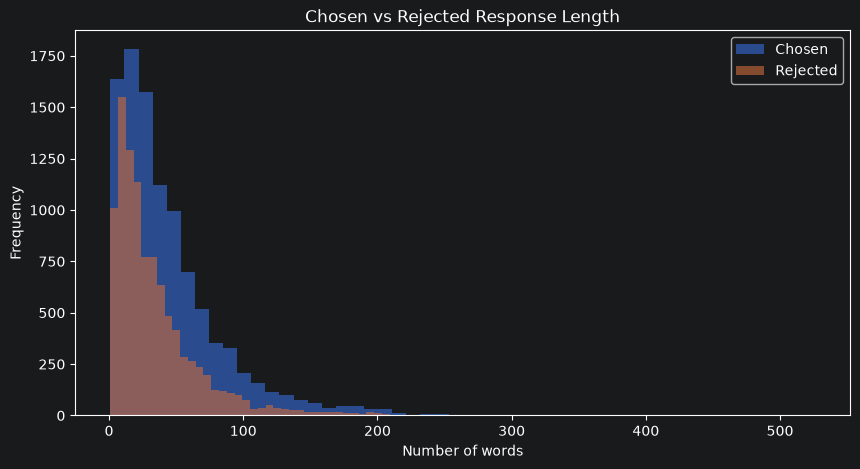

In [38]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["chosen_words"],
    bins=50,
    alpha=0.6,
    label="Chosen"
)

plt.hist(
    df["rejected_words"],
    bins=50,
    alpha=0.6,
    label="Rejected"
)

plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.title("Chosen vs Rejected Response Length")
plt.legend()

plt.show()

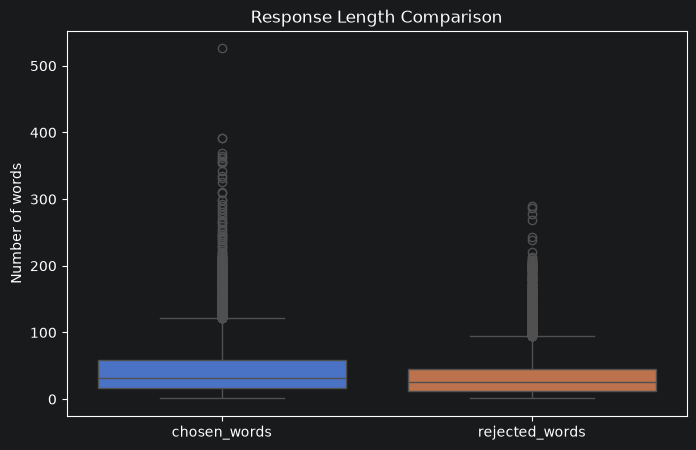

In [39]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df[
        ["chosen_words", "rejected_words"]
    ]
)

plt.title("Response Length Comparison")
plt.ylabel("Number of words")

plt.show()

In [40]:
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\keert\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [41]:
def get_word_frequency(text_series):

    words = []

    for text in text_series:

        tokens = text.lower().split()

        for word in tokens:

            word = word.strip(".,!?;:\"'()[]{}")

            if word and word not in stop_words:
                words.append(word)

    return Counter(words)

In [42]:
chosen_freq = get_word_frequency(
    df["chosen_response"]
)

rejected_freq = get_word_frequency(
    df["rejected_response"]
)

In [43]:
print("Top words in CHOSEN responses:")
print(chosen_freq.most_common(20))

Top words in CHOSEN responses:
[('like', 2344), ('also', 2060), ('it’s', 1793), ('want', 1583), ('would', 1404), ('could', 1388), ('think', 1349), ('you’re', 1312), ('people', 1270), ('might', 1177), ('one', 1175), ('help', 1166), ('i’m', 1089), ('know', 1086), ('make', 1066), ('sure', 1064), ('good', 1057), ('get', 1047), ('use', 1022), ('don’t', 877)]


In [44]:
print("\nTop words in REJECTED responses:")
print(rejected_freq.most_common(20))


Top words in REJECTED responses:
[('like', 1933), ('i’m', 1470), ('want', 1403), ('also', 1378), ('it’s', 1357), ('think', 1258), ('would', 1242), ('could', 1200), ('know', 1194), ('you’re', 1156), ('help', 1142), ('sure', 1105), ('people', 946), ('might', 921), ('don’t', 913), ('one', 888), ('good', 842), ('make', 814), ('get', 748), ('really', 709)]


In [45]:
from nltk.util import ngrams

In [46]:
def get_ngrams(text_series, n=2, top_k=20):

    ngram_counter = Counter()

    for text in text_series:

        tokens = [
            word.lower().strip(".,!?;:\"'()[]{}")
            for word in text.split()
            if word.lower() not in stop_words
        ]

        ngram_counter.update(
            ngrams(tokens, n)
        )

    return ngram_counter.most_common(top_k)

In [47]:
chosen_bigrams = get_ngrams(
    df["chosen_response"],
    n=2
)

rejected_bigrams = get_ngrams(
    df["rejected_response"],
    n=2
)

print("Top CHOSEN bigrams:")
print(chosen_bigrams)

print("\nTop REJECTED bigrams:")
print(rejected_bigrams)

Top CHOSEN bigrams:
[(('i’m', 'sure'), 258), (('would', 'like'), 254), (('you’re', 'welcome'), 214), (('don’t', 'know'), 201), (('sounds', 'like'), 191), (('make', 'sure'), 166), (('could', 'also'), 161), (('you’d', 'like'), 138), (('let', 'know'), 124), (('i’m', 'sorry'), 120), (('united', 'states'), 118), (('happy', 'help'), 116), (('could', 'try'), 114), (('might', 'want'), 113), (('many', 'different'), 113), (('you’re', 'looking'), 111), (('i’m', 'happy'), 103), (('you’ll', 'need'), 103), (('might', 'also'), 100), (('many', 'people'), 99)]

Top REJECTED bigrams:
[(('i’m', 'sure'), 386), (('don’t', 'know'), 286), (('would', 'like'), 261), (('i’m', 'sorry'), 216), (('sounds', 'like'), 166), (('you’re', 'welcome'), 157), (('you’d', 'like'), 134), (('let', 'know'), 131), (('happy', 'help'), 118), (('i’m', 'happy'), 114), (('make', 'sure'), 114), (('united', 'states'), 110), (('anything', 'else'), 98), (('you’re', 'asking'), 97), (('you’re', 'looking'), 96), (('i’m', 'glad'), 92), (('do

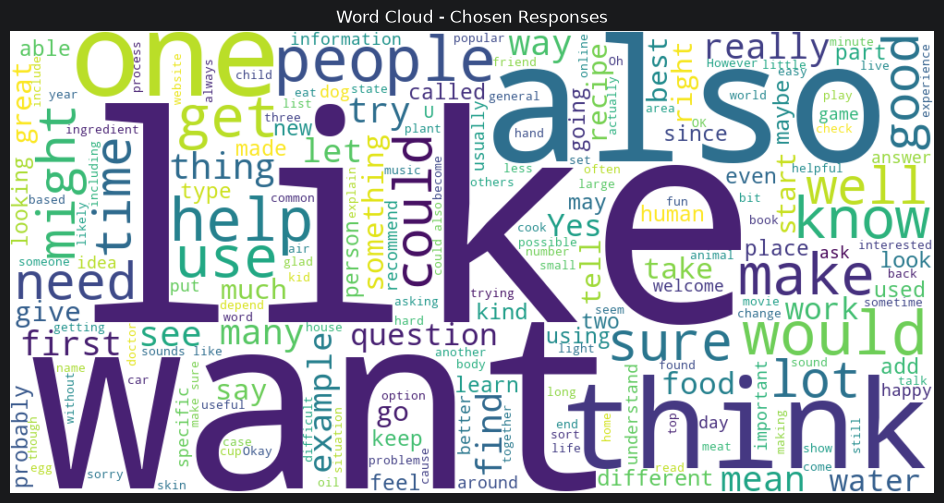

In [48]:
chosen_text = " ".join(
    df["chosen_response"]
)

wordcloud_chosen = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=stop_words
).generate(chosen_text)

plt.figure(figsize=(12, 6))

plt.imshow(
    wordcloud_chosen,
    interpolation="bilinear"
)

plt.axis("off")
plt.title("Word Cloud - Chosen Responses")

plt.show()

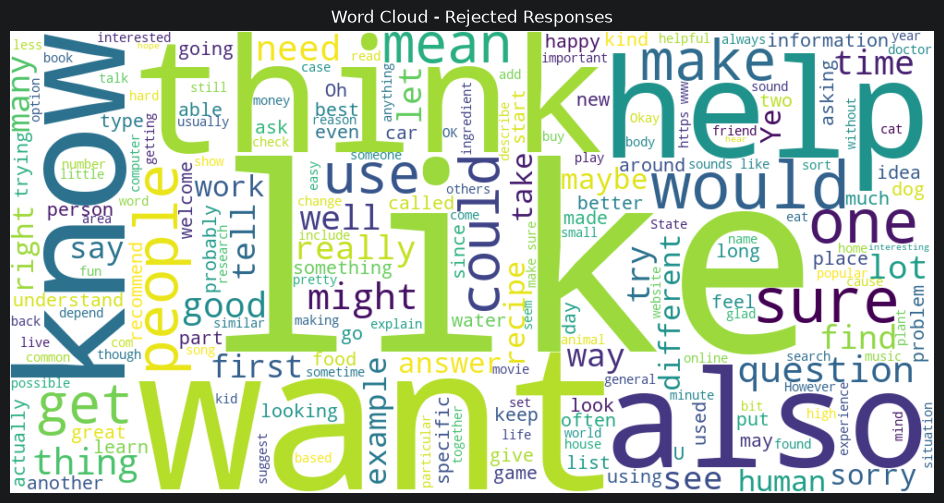

In [49]:
rejected_text = " ".join(
    df["rejected_response"]
)

wordcloud_rejected = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    stopwords=stop_words
).generate(rejected_text)

plt.figure(figsize=(12, 6))

plt.imshow(
    wordcloud_rejected,
    interpolation="bilinear"
)

plt.axis("off")
plt.title("Word Cloud - Rejected Responses")

plt.show()

In [50]:
df["chosen_longer"] = (
    df["chosen_words"] >
    df["rejected_words"]
)

print(
    "Chosen responses longer:",
    df["chosen_longer"].mean() * 100,
    "%"
)

Chosen responses longer: 57.651423987164065 %


In [51]:
print(
    "Chosen responses shorter:",
    (~df["chosen_longer"]).mean() * 100,
    "%"
)

Chosen responses shorter: 42.34857601283594 %


In [52]:
df["word_difference"] = (
    df["chosen_words"] -
    df["rejected_words"]
)

print(
    df["word_difference"].describe()
)

count    9972.000000
mean        9.702667
std        45.217529
min      -262.000000
25%       -11.000000
50%         5.000000
75%        27.000000
max       502.000000
Name: word_difference, dtype: float64


In [53]:
# Sentence count analysis

import nltk
from nltk.tokenize import sent_tokenize

nltk.download("punkt")
nltk.download("punkt_tab")

df["chosen_sentences"] = df["chosen_response"].apply(
    lambda x: len(sent_tokenize(x))
)

df["rejected_sentences"] = df["rejected_response"].apply(
    lambda x: len(sent_tokenize(x))
)

print("Chosen response sentence statistics:")
print(df["chosen_sentences"].describe())

print("\nRejected response sentence statistics:")
print(df["rejected_sentences"].describe())

print(
    "\nAverage chosen sentences:",
    round(df["chosen_sentences"].mean(), 2)
)

print(
    "Average rejected sentences:",
    round(df["rejected_sentences"].mean(), 2)
)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\keert\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\keert\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Chosen response sentence statistics:
count    9972.000000
mean        2.847172
std         2.364556
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        31.000000
Name: chosen_sentences, dtype: float64

Rejected response sentence statistics:
count    9972.000000
mean        2.395909
std         1.858902
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        49.000000
Name: rejected_sentences, dtype: float64

Average chosen sentences: 2.85
Average rejected sentences: 2.4


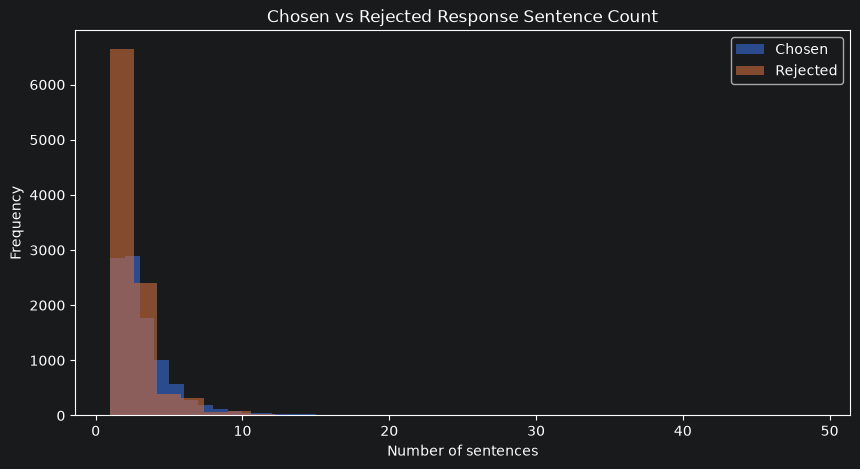

In [54]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["chosen_sentences"],
    bins=30,
    alpha=0.6,
    label="Chosen"
)

plt.hist(
    df["rejected_sentences"],
    bins=30,
    alpha=0.6,
    label="Rejected"
)

plt.xlabel("Number of sentences")
plt.ylabel("Frequency")
plt.title("Chosen vs Rejected Response Sentence Count")
plt.legend()

plt.show()

In [55]:
df["chosen_more_sentences"] = (
    df["chosen_sentences"] > df["rejected_sentences"]
)

df["rejected_more_sentences"] = (
    df["rejected_sentences"] > df["chosen_sentences"]
)

df["same_sentence_count"] = (
    df["chosen_sentences"] == df["rejected_sentences"]
)

print(
    "Chosen has more sentences:",
    round(df["chosen_more_sentences"].mean() * 100, 2),
    "%"
)

print(
    "Rejected has more sentences:",
    round(df["rejected_more_sentences"].mean() * 100, 2),
    "%"
)

print(
    "Both have the same sentence count:",
    round(df["same_sentence_count"].mean() * 100, 2),
    "%"
)

Chosen has more sentences: 43.01 %
Rejected has more sentences: 30.81 %
Both have the same sentence count: 26.18 %


# Key EDA Findings

- The dataset contains 9,972 clean human preference pairs.
- Chosen responses are longer on average than rejected responses.
- Chosen responses also contain slightly more sentences on average.
- Chosen and rejected responses have substantial vocabulary overlap.
- Word frequency and response length alone cannot explain human preference.
- These findings motivate the use of TF-IDF features and machine-learning models for preference prediction.